# Fase 1: Construyendo el Multiverso del Jugador (Min. 4 Dimensiones)

Creen un Jupyter Notebook nuevo, carguen el dataset proporcionado en GitHub y seleccionen a su "Jugador Estrella" (puede ser el jugador con más goles o su favorito del dataset, la decisión es suya).

**Misión:**

1. Construyan la matriz multidimensional **X** seleccionando al menos **4 características numéricas (pueden ser más)** continuas **(float)** que definan el rendimiento del jugador (por ejemplo: Goles, Asistencias, Minutos_Jugados, Precisión_Pases, Recuperaciones, etc.).
2. Creen un vector para su jugador estrella y otro vector para el resto de los candidatos.
3. ***Pregunta de control:*** Antes de medir cualquier distancia, ¿qué operación de la Unidad II deben aplicarle obligatoriamente a estas 4 columnas para que los Minutos_Jugados (rango en miles) no aplasten matemáticamente a los Goles (rango en decenas)? Apliquen esa transformación en el código.

In [ ]:
import pandas as pd
import numpy as np

# Carga y limpieza básica
df = pd.read_csv('players_data-2025_2026.csv')

print(f"Dimensiones del dataset original: {df.shape}")
df[['Player', 'Squad', 'Pos', 'Min', 'Gls', 'Ast']].head()


Dimensiones del dataset original: (2839, 102)


,Player,Squad,Pos,Min,Gls,Ast
0,Brenden Aaronson,Leeds United,"MF,FW",2449,4,5
1,Jerome Abbey,Wolves,MF,17,0,0
2,Zach Abbott,Nottingham Forest,DF,164,0,0
3,Jones El-Abdellaoui,Celta Vigo,"MF,FW",681,2,0
4,Himad Abdelli,Marseille,MF,138,0,0


In [44]:
features = ['Min', 'Gls', 'Ast', 'Sh']

df.drop_duplicates(subset=['Player'], inplace=True)
df.dropna(subset=features, inplace=True)
df.reset_index(drop=True, inplace=True)

X = ((df[features] - df[features].min()) / (df[features].max() - df[features].min())).to_numpy()

star_idx = df[df['Player'] == 'Harry Kane'].index[0]
vector_estrella = X[star_idx]

In [45]:
candidatos_mask = df.index != star_idx
X_cand = X[candidatos_mask]
df_cand = df[candidatos_mask].reset_index(drop=True)

print("Datos listos. Candidatos preparados:", len(df_cand))
print("Vector normalizado de Harry Kane:", np.round(vector_estrella, 3))

Datos listos. Candidatos preparados: 2686
Vector normalizado de Harry Kane: [0.695 1.    0.238 0.815]


# Fase 2: El Duelo de Distancias (Euclidiana vs. Manhattan)

La **distancia euclidiana** (la línea recta) no es la única forma de viajar por el espacio vectorial. Existen otras métricas como la **Distancia Manhattan (Norma L1)**, que calcula la distancia moviéndose estrictamente en ángulos rectos, como si un taxi navegara por las cuadras de Nueva York, también es conocida como la distancia del taxista.

**Misión:**

1. Investiguen y escriban en su Notebook la fórmula matemática de la **Distancia Manhattan**.
2. Programen una celda para encontrar al jugador más similar a su estrella usando la Distancia Euclidiana. Impriman el nombre del reemplazo sugerido.
3. En la siguiente celda, busquen al reemplazo calculando la **Distancia Manhattan (deberán generar una función custom para calcular esta distancia)**.
4. **Análisis Crítico:** ¿El algoritmo sugirió al mismo jugador en ambos casos? Como ingenieros, expliquen en un bloque de Markdown las diferencias observables entre la Distancia Euclidiana comparado con la Distancia Manhattan.

In [60]:
df_cand['dist_euc'] = np.sqrt(np.sum((X_cand - vector_estrella)**2, axis=1))
euc_top = df_cand.sort_values('dist_euc').iloc[0]

def manhattan(a, b):
    return np.sum(np.abs(a - b), axis=1)

In [61]:

df_cand['dist_man'] = manhattan(X_cand, vector_estrella)
man_top = df_cand.sort_values('dist_man').iloc[0]

print("Reemplazo Euclidiano:", euc_top['Player'], "| Distancia:", round(euc_top['dist_euc'], 4))
print("Reemplazo Manhattan:", man_top['Player'], "| Distancia:", round(man_top['dist_man'], 4))

Reemplazo Euclidiano: Erling Haaland | Distancia: 0.337
Reemplazo Manhattan: Kylian Mbappé | Distancia: 0.5554


En este caso Haaland tiene menos distancia hacia Kane ya que Elevar al cuadrado penaliza severamente a los candidatos que tienen una desviación grande en una sola dimensión. Mbappé tiene una brecha notable en goles frente a Kane ($\vert{}\Delta \text{Gls}\vert{} \approx 0.306$), por lo que el término al cuadrado $(0.306)^2 \approx 0.093$ eleva drásticamente su distancia.
Haaland, en cambio, reparte sus diferencias de forma más equilibrada entre todas las variables, resultando en una distancia geométrica en línea recta más corta.

# Fase 3: El Reto de Visualización en 4D (Investigación Independiente)

El director técnico quiere ver un reporte visual de por qué el jugador que sugirieron es el más parecido al original.

El problema físico es que ustedes seleccionaron 4 (o más) características. Los seres humanos solo podemos ver un eje X, un eje Y y un eje Z.

**Misión de Investigación:**

1. Investiguen y elijan **una** técnica o librería en Python que les permita proyectar visualmente vectores de 4 dimensiones o más en una pantalla 2D.(Pistas que pueden investigar: Gráficos de Radar / Spider Charts, Coordenadas Paralelas, o el uso de color/tamaño como cuartas dimensiones en un Scatter 3D).
2. Implementen el código para visualizar a su "Jugador Estrella" junto al "Reemplazo Sugerido" y a un "Tercer Jugador Aleatorio" (para ver el contraste).
3. Entreguen el Notebook documentado comprobando visualmente que los vectores de su estrella y su clon están, efectivamente, muy cerca en el hiperespacio.

In [ ]:
import matplotlib.pyplot as plt
from pandas.plotting import parallel_coordinates

idx_reemplazo = df_cand[df_cand['Player'] == euc_top['Player']].index[0]

idx_aleatorio = np.random.choice(len(df_cand))

df_plot = pd.DataFrame([
    vector_estrella,
    X_cand[idx_reemplazo],
    X_cand[idx_aleatorio]
], columns=features)

df_plot['Jugador'] = [
    'Harry Kane (Estrella)',
    f"{euc_top['Player']} (Clon)",
    f"{df_cand.loc[idx_aleatorio, 'Player']} (Aleatorio)"
]

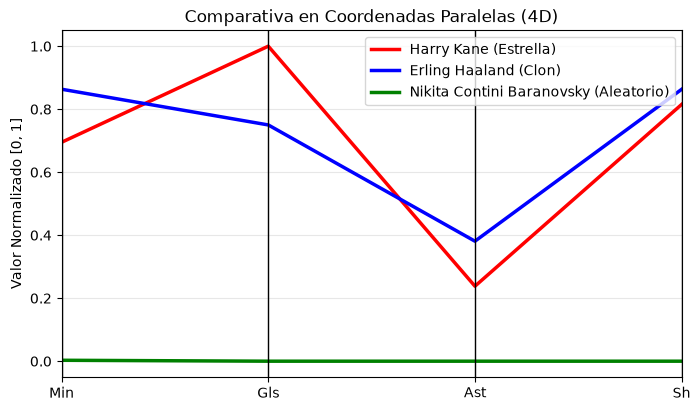

In [59]:
plt.figure(figsize=(8, 4.5))
parallel_coordinates(df_plot, 'Jugador', color=['RED', 'BLUE', 'GREEN'], linewidth=2.5)

plt.title('Comparativa en Coordenadas Paralelas (4D)')
plt.ylabel('Valor Normalizado [0, 1]')
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')
plt.show()